# **EDA 실습 03**


# **데이터셋 설명**
데이터 출처: Video Game Sales (Kaggle, vgchartz.com 판매량 집계 기반) — 1980~2017년 출시 게임 16,539종

| 컬럼명 | 설명 |
|---|---|
| Name | 게임 이름 |
| Platform | 출시 플랫폼 (Wii, PS4, NES 등) |
| Year | 출시 연도 |
| Genre | 장르 |
| Publisher | 배급사 |
| NA_Sales | 북미 판매량 (단위: 백만 장) |
| EU_Sales | 유럽 판매량 (단위: 백만 장) |
| JP_Sales | 일본 판매량 (단위: 백만 장) |
| Other_Sales | 그 외 지역 판매량 (단위: 백만 장) |
| Global_Sales | 전세계 판매량 (단위: 백만 장) |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/videogame_sales.csv")
df.head()

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Kaboom!,2600,1980.0,Misc,Activision,1.07,0.07,0.0,0.01,1.15
1,Boxing,2600,1980.0,Fighting,Activision,0.72,0.04,0.0,0.01,0.77
2,Ice Hockey,2600,1980.0,Sports,Activision,0.46,0.03,0.0,0.01,0.49
3,Freeway,2600,1980.0,Action,Activision,0.32,0.02,0.0,0.00,0.34
4,Bridge,2600,1980.0,Misc,Activision,0.25,0.02,0.0,0.00,0.27


In [2]:
ans = []

#### **Q1. 전 세계에서 가장 많이 팔린 게임은 무엇일까?**

- 테트리스, 마리오, 포켓몬 게임중 하나일 것 같다.
- 이 가설을 검증할 정보를 찾고 시각화한다.
- 전세게 판매량 (global 기준) 6위 게임의 이름을 구하라.

In [3]:
# code here
top10 = df.sort_values("Global_Sales", ascending=False).head(10)

<Axes: xlabel='Global_Sales', ylabel='Name'>

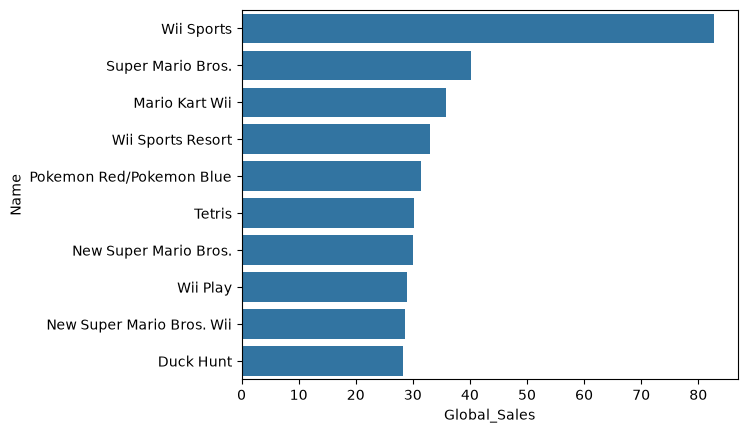

In [93]:
import seaborn as sns
sns.barplot(top10, x='Global_Sales', y='Name', orient='horizontal')

In [94]:
q1 = top10.head(6).tail(1)['Name'].values[0]
ans.append(q1)

#### **Q2. 닌텐도는의 게임의 인기는 대륙별로 다를까?**

- 북미, 유럽 유저와 일본 유저의 성향이 달라 선호하는 게임이 달랐을 것으로 예상한다.
- 이 가설을 검증할 정보를 찾고 시각화한다.
- [1] 글로벌 판매량 top 10게임 중 일본 게임 유저들이 가장 많이 구매한 게임명을 찾아라.

  [2] 글로벌 판매량 top 10 북미에서 일본보다 압도적으로 많이 팔린 게임이 몇배나 많이 팔렸는지를 소수점 2자리까지 구하라.

In [4]:
# code here
sales_df = top10[["Name", "JP_Sales", "NA_Sales", "Global_Sales"]]
sales_df

,Name,JP_Sales,NA_Sales,Global_Sales
6675,Wii Sports,3.77,41.49,82.74
129,Super Mario Bros.,6.81,29.08,40.24
9128,Mario Kart Wii,3.79,15.85,35.82
10564,Wii Sports Resort,3.28,15.75,33.00
852,Pokemon Red/Pokemon Blue,10.22,11.27,31.37
194,Tetris,4.22,23.20,30.26
6676,New Super Mario Bros.,6.50,11.38,30.01
6677,Wii Play,2.93,14.03,29.02
10565,New Super Mario Bros. Wii,4.70,14.59,28.62
113,Duck Hunt,0.28,26.93,28.31


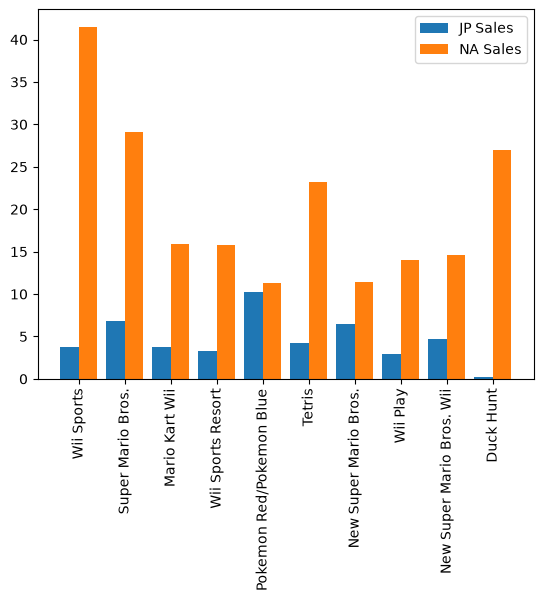

In [96]:
import matplotlib.pyplot as plt
import numpy as np 
li = np.arange(len(top10))
width = 0.4
plt.bar(li-(width/2), top10['JP_Sales'], width=width, label="JP Sales")
plt.bar(li+(width/2), top10['NA_Sales'], width=width, label="NA Sales")
plt.xticks(li, top10["Name"], rotation=90)
plt.legend()
plt.show()

In [97]:
q2 = top10.loc[top10["JP_Sales"].idxmax()]["Name"]
ans.append(q2)

In [98]:
#북미에서 가장 압도적으로 많이 팔린 게임의 비중
comp_df = top10["NA_Sales"] / top10["JP_Sales"]
q3 = comp_df.max().round(2)
ans.append(q3)

#### **Q3. 일본과 북미는 좋아하는 장르가 다를까?**

- 이 가설을 검증할 정보를 찾고 시각화한다.
- 일본이 북미보다 선호하는 (판매량이 많은) 유일한 게임 장르를 찾는다.

In [5]:
# code here
df.groupby("Genre")[["JP_Sales", "NA_Sales"]].sum()

,JP_Sales,NA_Sales
Genre,,
Action,159.49,877.54
Adventure,51.99,105.67
Fighting,87.35,221.92
Misc,107.72,404.67
Platform,130.77,447.05
Puzzle,57.31,123.78
Racing,56.69,359.42
Role-Playing,352.26,327.28
Shooter,38.28,582.59


In [7]:
gdf = df.groupby("Genre")[["JP_Sales", "NA_Sales"]].sum()
q4 = gdf[gdf["JP_Sales"] > gdf["NA_Sales"]].reset_index()['Genre'].values[0]
#ans.append(q4)
q4

'Role-Playing'

#### **Q4. 게임 판매량은 최근으로 올수록 계속 늘어났을까?**

- 게임 산업이 계속 성장해왔으니, 판매량도 최근 연도일수록 더 많을 것 같다.
- 이 가설을 검증할 정보를 찾고 시각화한다.
- 연도별 전세계 판매량 합계를 선 그래프로 그리고, 판매량이 가장 많았던 연도를 찾아라.(정수로 저장한다)

In [101]:
ydf = df.groupby("Year")['Global_Sales'].sum()
ydf.head()

Year
1980.0    11.38
1981.0    35.77
1982.0    28.86
1983.0    16.79
1984.0    50.36
Name: Global_Sales, dtype: float64

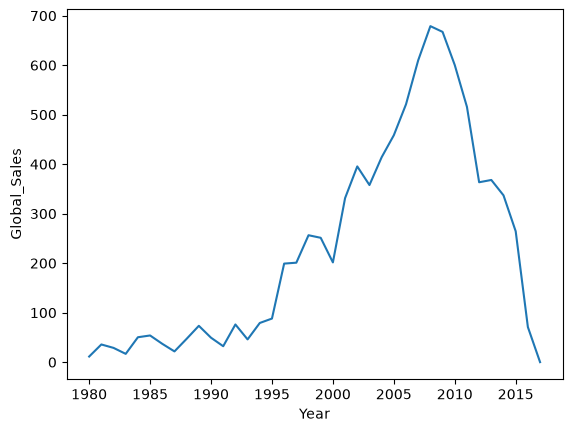

In [102]:
sns.lineplot(ydf)
plt.show()

In [103]:
q5 = ydf.idxmax()
ans.append(int(q5))

#### **Q5. 닌텐도가 만든 게임은 평균적으로 훨씬 많이 팔릴까?**

- 닌텐도는 마리오, 젤다처럼 확실한 인기 IP가 많으니, 게임 한 편당 평균 판매량도 다른 회사보다 훨씬 높을 것 같다.
- 이 가설을 검증할 정보를 찾고 시각화한다.
- 닌텐도(Nintendo)가 배급한 게임과 그 외의 게임의 평균 전세계 판매량을 구하고, 두 값의 차이를 소수점 2자리까지 구한다.

In [104]:
# code here
df['is_Nintendo'] = df['Publisher'] == "Nintendo"

In [105]:
df.head()

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,is_Nintendo
0,Kaboom!,2600,1980.0,Misc,Activision,1.07,0.07,0.0,0.01,1.15,False
1,Boxing,2600,1980.0,Fighting,Activision,0.72,0.04,0.0,0.01,0.77,False
2,Ice Hockey,2600,1980.0,Sports,Activision,0.46,0.03,0.0,0.01,0.49,False
3,Freeway,2600,1980.0,Action,Activision,0.32,0.02,0.0,0.00,0.34,False
4,Bridge,2600,1980.0,Misc,Activision,0.25,0.02,0.0,0.00,0.27,False


In [106]:
nintendo_mean = df[df['is_Nintendo'] == 1]["Global_Sales"].mean()
other_mean = df[df['is_Nintendo'] == 0]["Global_Sales"].mean()

In [107]:
nintendo_mean, other_mean

(np.float64(2.541337126600285), np.float64(0.44952702702702696))

In [108]:
q6 = (nintendo_mean - other_mean).round(2)
ans.append(q6)

### **Q6. 제출**

- 위에서 찾은 각 정보들을 DataFrame의 "ans" 컬럼에 순서대로 담아 .csv 파일로 저장하여 제출한다.
- 총 기입되는 행의 개수는 6개이다.

In [109]:
# code here
s = pd.DataFrame(ans, columns = ["ans"])

In [110]:
s.to_csv("submission.csv", index=False)